## Load Dataset

Dataset Link: https://drive.google.com/drive/folders/117doQ-TqMB9BOR7Sa-Y5byV57aVDzE4q?usp=sharing
Video Link: https://youtu.be/aM9K2Cgu_fw

Sets up the environment by extracting the furniture image dataset and importing the libraries and settings needed throughout the notebook.

In [ ]:

# --- Local paths ---
import os
BASE_DIR = os.getcwd()

# --- Unzip Dataset ---
import zipfile

zip_path     = os.path.join(BASE_DIR, 'furniture.zip')
extract_path = os.path.join(BASE_DIR, 'furniture')

if not os.path.exists(extract_path):
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Done.")
else:
    print("Dataset already extracted, skipping.")

# --- Core ---
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets, models

import numpy as np
import time

# --- Visualisation ---
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# --- Stats ---
from scipy.stats import pearsonr

# --- Image Processing ---
from PIL import Image
import scipy.ndimage as ndimage

# --- Metrics ---
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    f1_score,
    classification_report
)

# --- Reproducibility ---
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# --- Device ---
device = torch.device('cpu')
print(f"Using device: {device}")

# --- Dataset Config ---
CLASSES = ['bed', 'desk', 'lamp', 'sofa', 'wardrobe']
NUM_CLASSES = len(CLASSES)
IMG_SIZE = 128
BATCH_SIZE = 8


Dataset already extracted, skipping.
Using device: cpu


## Initialise Transforms and Dataloaders

Prepares images for training by applying random adjustments (cropping, flipping, colour shifts) to increase variety, then organises them into batches ready for the model to process.

In [2]:

import torchvision.transforms as transforms
import torch

# --- Transforms ---
# Normalisation values for AlexNet
IMAGEA1_MEAN = [0.485, 0.456, 0.406]
IMAGEA1_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop((IMG_SIZE, IMG_SIZE), scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGEA1_MEAN, std=IMAGEA1_STD),
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGEA1_MEAN, std=IMAGEA1_STD),
])

# --- Load Datasets ---
train_dataset = datasets.ImageFolder(os.path.join(extract_path, 'train'), transform=train_transform)
test_dataset = datasets.ImageFolder(os.path.join(extract_path, 'test'),  transform=test_transform)

# --- Dataloaders ---
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=False)
test_loader  = torch.utils.data.DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=False)

print(f"Dataloaders initialized. Train batches: {len(train_loader)}, Test batches: {len(test_loader)}")

# --- Helpers ---
idx_to_class = {v: k for k, v in train_dataset.class_to_idx.items()}

def denorm(tensor):
    mean = torch.tensor(IMAGEA1_MEAN).view(3, 1, 1)
    std  = torch.tensor(IMAGEA1_STD).view(3, 1, 1)
    return (tensor * std + mean).clamp(0, 1)


Dataloaders initialized. Train batches: 13, Test batches: 7


## Part II - Finetuning AlexNet

Adapts a pre-trained image recognition network to identify five furniture categories (bed, desk, lamp, sofa, wardrobe) by retraining only its final classification layers.

/home/dan/Desktop/CVAssignment/.venv/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/dan/Desktop/CVAssignment/.venv/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

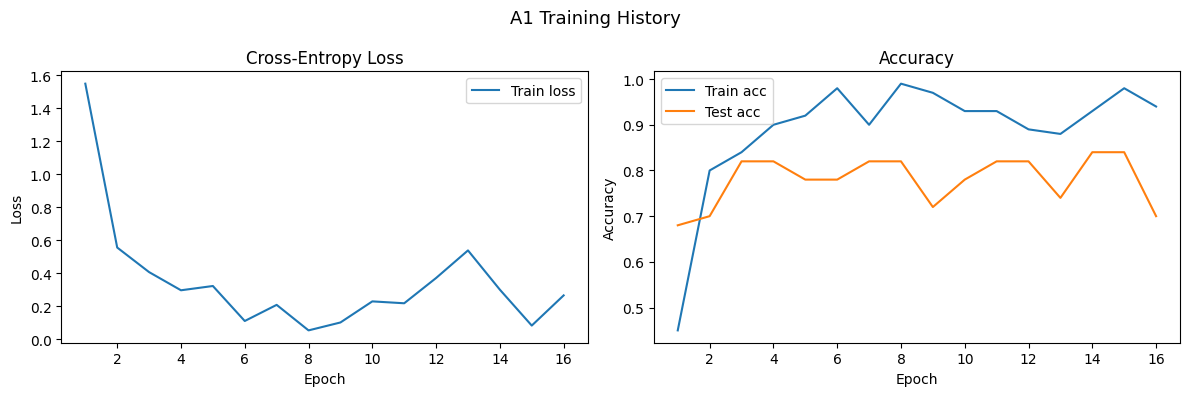

In [3]:
import torch.nn as nn
from torch import optim
import torchvision

# --- 1. Load pretrained AlexNet (torchvision) ---
a1 = torchvision.models.alexnet(pretrained=True)
a1.to(device)
print(a1)

# --- 2. Print parameter count per layer ---
print(f"\n{'Layer':<40} {'# Params':>12}")
print("-" * 54)

total_params = 0
for name, param in a1.named_parameters():
    n = param.numel()
    total_params += n
    print(f"  {name:<38} {n:>12,}")

print("-" * 54)
print(f"  {'TOTAL':<38} {total_params:>12,}")

# Heaviest layers
print("\nTop 5 layers by parameter count:")
layer_params = [(name, p.numel()) for name, p in a1.named_parameters()]
for name, n in sorted(layer_params, key=lambda x: x[1], reverse=True)[:5]:
    print(f"  {name:<40} {n:>10,}  ({100*n/total_params:.1f}%)")

# --- 3. Freeze feature layers, replace final layer ---
for param in a1.parameters():
    param.requires_grad = False

for param in a1.classifier.parameters():
    param.requires_grad = True

# Replace final layer
num_ftrs = a1.classifier[6].in_features
a1.classifier[6] = nn.Linear(num_ftrs, NUM_CLASSES)

# Increase dropout beyond default 0.5 for key classification layers
a1.classifier[0] = nn.Dropout(p=0.6)
a1.classifier[3] = nn.Dropout(p=0.6)

a1.to(device)

# Print exactly which layers will update
print("Params to learn:")
params_to_update = []
for name, param in a1.named_parameters():
    if param.requires_grad:
        params_to_update.append(param)
        print(f"\t{name}")

# --- 4. Training  ---
num_epochs = 16
lr = 0.0002
wd_lambda = 0.001

loss = nn.CrossEntropyLoss()
trainer = optim.Adam(params_to_update, lr=lr, weight_decay=wd_lambda)

def train_validate(net, train_iter, test_iter, num_epochs, trainer, loss, label=""):
    history = {'train_loss': [], 'train_acc': [], 'test_acc': []}
    print(f"Training on {device}")

    for epoch in range(1, num_epochs + 1):
        net.train()
        train_loss_sum, train_correct, n = 0.0, 0, 0

        for X, y in train_iter:
            X, y = X.to(device), y.to(device)
            trainer.zero_grad()
            y_hat = net(X)
            l = loss(y_hat, y)
            l.backward()
            trainer.step()

            train_loss_sum += l.item() * X.size(0)
            train_correct += (y_hat.argmax(1) == y).sum().item()
            n += X.size(0)

        # Eval
        net.eval()
        test_correct = 0
        with torch.no_grad():
            for X, y in test_iter:
                X, y = X.to(device), y.to(device)
                test_correct += (net(X).argmax(1) == y).sum().item()

        train_loss = train_loss_sum / n
        train_acc = train_correct  / n
        test_acc = test_correct   / len(test_iter.dataset)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['test_acc'].append(test_acc)

        print(f"epoch {epoch:>3}, loss {train_loss:.4f}, "
              f"train acc {train_acc:.3f}, test acc {test_acc:.3f}")

    return history

# Updated paths to be in base directory
A1_WEIGHTS = os.path.join(BASE_DIR, 'a1_weights.pth')
A1_HISTORY = os.path.join(BASE_DIR, 'a1_history.npy')

if os.path.exists(A1_WEIGHTS):
    a1.load_state_dict(torch.load(A1_WEIGHTS, map_location=device))
    a1.to(device)
    history_a1 = np.load(A1_HISTORY, allow_pickle=True).item()
    print(f"A1 weights loaded from {A1_WEIGHTS} — skipping training.")
else:
    history_a1 = train_validate(a1, train_loader, test_loader,
                                num_epochs, trainer, loss, label="A1")
    torch.save(a1.state_dict(), A1_WEIGHTS)
    np.save(A1_HISTORY, history_a1)
    print(f"A1 weights and history saved to {BASE_DIR}.")

# --- Plot training history ---
epochs = range(1, len(history_a1['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("A1 Training History", fontsize=13)

ax1.plot(epochs, history_a1['train_loss'], label='Train loss')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax1.set_title('Cross-Entropy Loss'); ax1.legend()

ax2.plot(epochs, history_a1['train_acc'], label='Train acc')
ax2.plot(epochs, history_a1['test_acc'],  label='Test acc')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy')
ax2.set_title('Accuracy'); ax2.legend()

plt.tight_layout()
plt.show()

## Part III - Filter Comparison

Examines the low-level patterns the network learned to detect in its first layer and compares them against classic hand-crafted image filters such as edge detectors and blur kernels.

All filter sanity checks passed.
Conv1 weight tensor: (64, 3, 11, 11)  (64 filters)


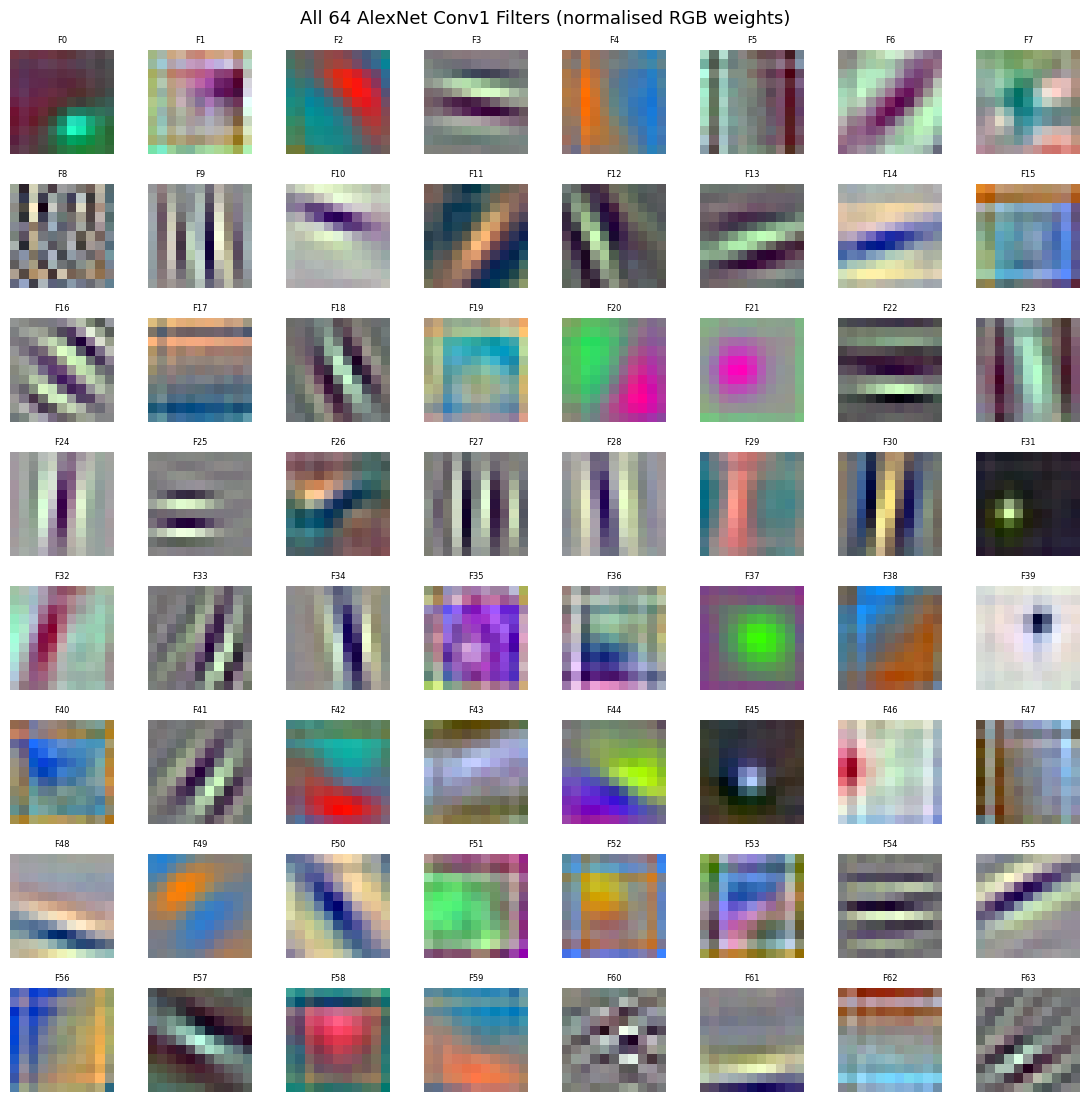

Similarity matrices computed: (4, 64)


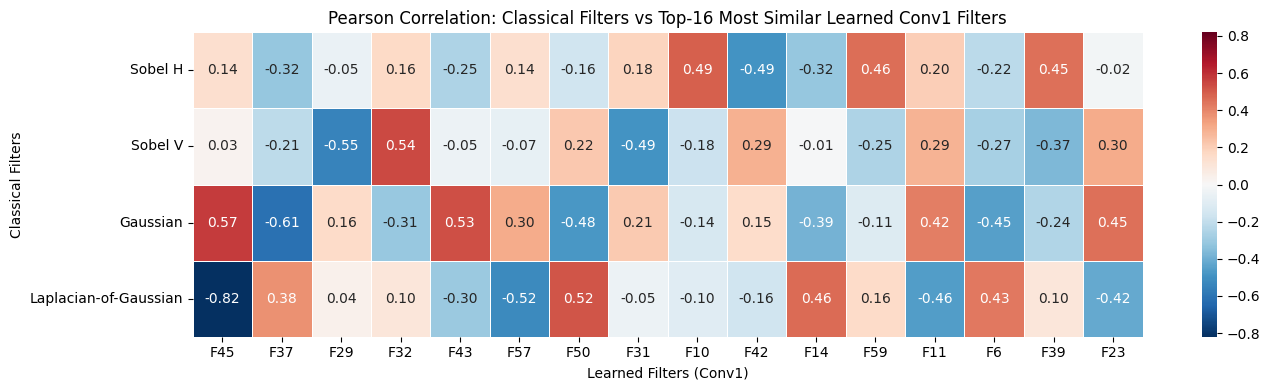


Classical     Filter   Pearson   Cosine    Frob
-----------------------------------------------
Sobel H           10    +0.490   +0.490   1.010
Sobel V           29    -0.549   -0.549   1.760
Gaussian          37    -0.613   -0.508   1.737
Laplacian-of-Gaussian      45    -0.820   -0.820   1.908


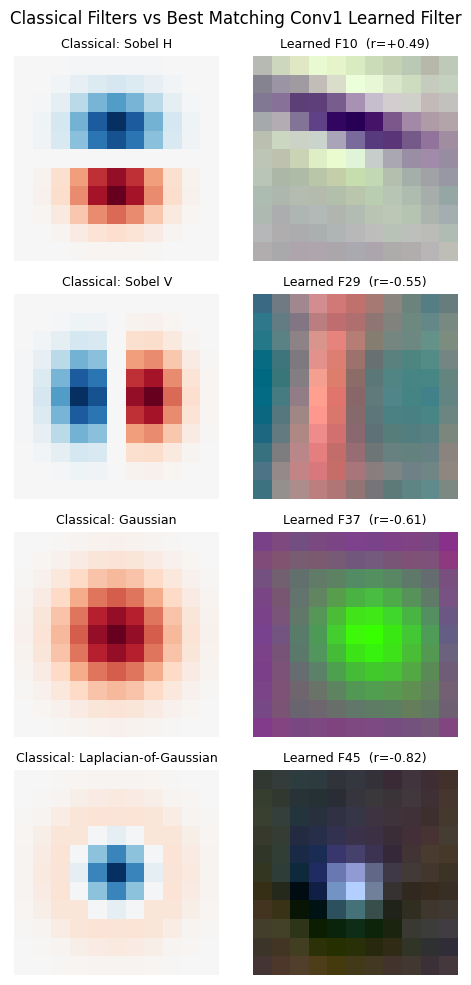

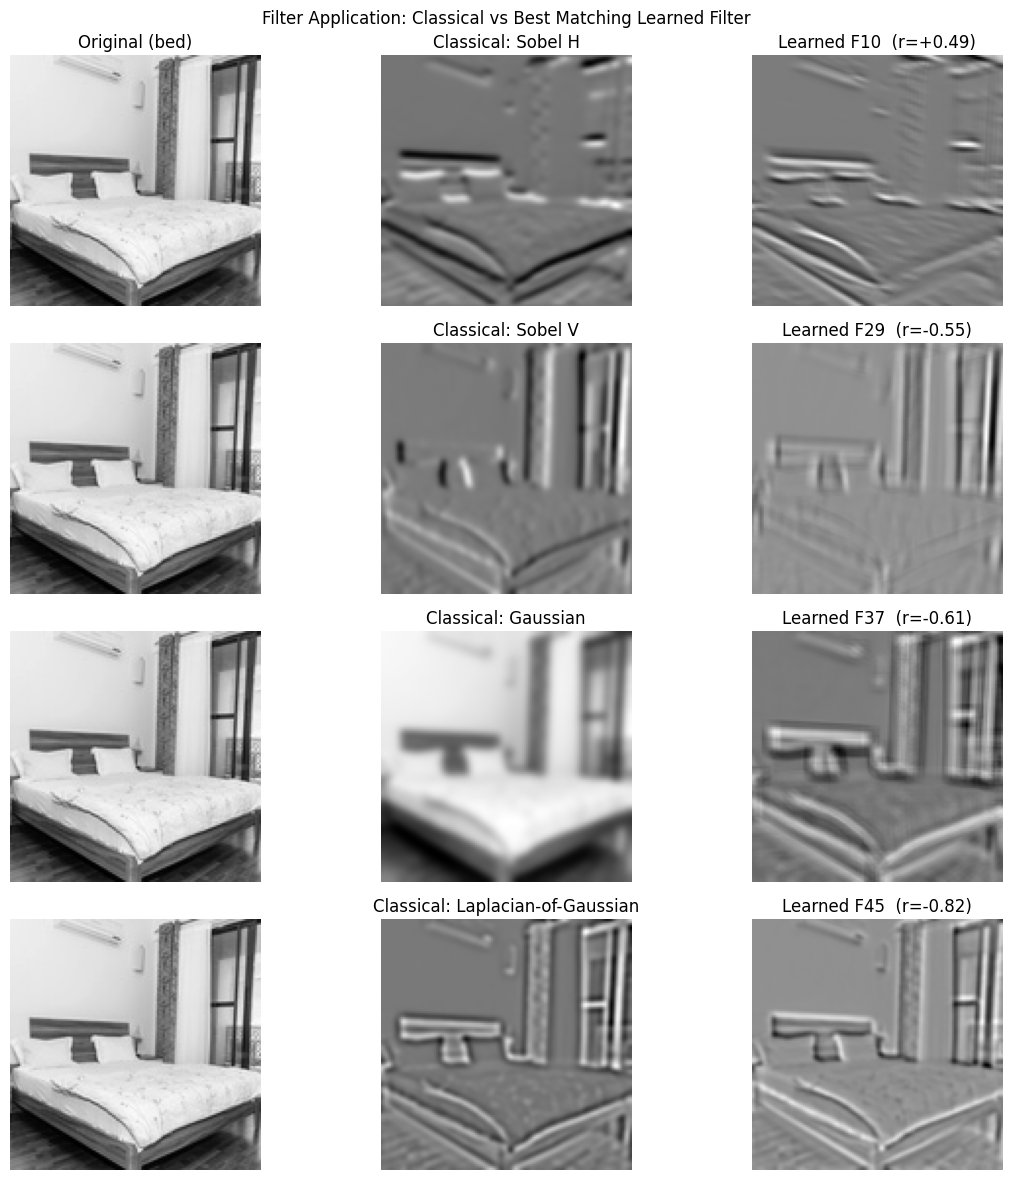

In [4]:
import numpy as np
import scipy.ndimage as ndimage
from scipy.stats import pearsonr
from scipy.special import comb
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# --- Define classical filters as native 11x11 kernels (to match Conv1) ---

# Helper Functions for Native Sobel Filters
def sobel_1d_smooth(size):
    """Binomial smoothing coefficients (a row of Pascal's triangle)."""
    return np.array([comb(size - 1, k, exact=True) for k in range(size)],
                    dtype=np.float32)

def sobel_1d_deriv(size):
    """[-1, 0, 1] convolved with binomial(size-2); always length `size`."""
    return np.convolve(np.array([-1, 0, 1], dtype=np.float32),
                       sobel_1d_smooth(size - 2)).astype(np.float32)

def make_sobel(size=11):
    """(sobel_h, sobel_v): h detects horizontal edges, v detects vertical."""
    smooth, deriv = sobel_1d_smooth(size), sobel_1d_deriv(size)
    return (np.outer(deriv, smooth).astype(np.float32),
            np.outer(smooth, deriv).astype(np.float32))

# Native Gaussian (sigma=2.0 gives falloff across an 11-wide kernel).
def gaussian_kernel(size=11, sigma=2.0):
    ax = np.arange(size) - size // 2
    g = np.exp(-ax ** 2 / (2 * sigma ** 2))
    g = g / g.sum()
    return np.outer(g, g).astype(np.float32)

# Native Laplacian-of-Gaussian
def log_kernel(size=11, sigma=1.6):
    ax = np.arange(size) - size // 2
    xx, yy = np.meshgrid(ax, ax)
    r2 = xx ** 2 + yy ** 2
    log = (r2 - 2.0 * sigma ** 2) / (sigma ** 4) * np.exp(-r2 / (2.0 * sigma ** 2))
    log = log - log.mean()
    return log.astype(np.float32)

sobel_h_11, sobel_v_11 = make_sobel(size=11)
CLASSICAL_FILTERS = {
    'Sobel H':   sobel_h_11,
    'Sobel V':   sobel_v_11,
    'Gaussian':  gaussian_kernel(size=11, sigma=2.0),
    'Laplacian-of-Gaussian': log_kernel(size=11, sigma=1.6),
}

# --- Sanity checks ---
_h3, _v3 = make_sobel(size=3)
assert np.allclose(_h3, [[-1, -2, -1], [0, 0, 0], [1, 2, 1]]), f"sobel_h 3x3:\n{_h3}"
assert np.allclose(_v3, [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]), f"sobel_v 3x3:\n{_v3}"
for _name, _k in CLASSICAL_FILTERS.items():
    assert _k.shape == (11, 11), f"'{_name}' has shape {_k.shape}"
    assert _k.dtype == np.float32, f"'{_name}' has dtype {_k.dtype}"
assert abs(CLASSICAL_FILTERS['Gaussian'].sum() - 1.0) < 1e-4, "Gaussian must sum to 1"
assert abs(CLASSICAL_FILTERS['Laplacian-of-Gaussian'].sum()) < 1e-4, "LoG must sum to 0 (DC rejection)"
print("All filter sanity checks passed.")

classical_names = list(CLASSICAL_FILTERS.keys())

# --- Extract Conv1 filters from A1 ---
conv1_weights = a1.features[0].weight.data.cpu()    # (num_filters, 3, 11, 11)
num_filters = conv1_weights.shape[0]
learned_grey = conv1_weights.numpy().mean(axis=1)  # average RGB -> (num_filters, 11, 11)

def normalise_filter(f):
    """Normalise a filter to [0, 1] for display."""
    f = f - f.min()
    return f / (f.max() + 1e-8)

print(f"Conv1 weight tensor: {tuple(conv1_weights.shape)}  ({num_filters} filters)")

# --- Show every Conv1 filter (64 total) ---
n_cols = 8
n_rows = int(np.ceil(num_filters / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 1.4, n_rows * 1.4))
fig.suptitle(f"All {num_filters} AlexNet Conv1 Filters (normalised RGB weights)", fontsize=13)
for i, ax in enumerate(axes.flat):
    if i < num_filters:
        ax.imshow(normalise_filter(conv1_weights[i]).permute(1, 2, 0).numpy())
        ax.set_title(f"F{i}", fontsize=6)
    ax.axis('off')
plt.tight_layout()
plt.show()

# --- Similarity matrices: Pearson, cosine, and Frobenius distance ---
def cosine_sim(a, b):
    a, b = a.flatten(), b.flatten()
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-8))

def frobenius_dist(a, b):
    a = a.flatten(); a = a / (np.linalg.norm(a) + 1e-8)
    b = b.flatten(); b = b / (np.linalg.norm(b) + 1e-8)
    return float(np.linalg.norm(a - b))

num_classical = len(CLASSICAL_FILTERS)
pearson_matrix = np.zeros((num_classical, num_filters))
cosine_matrix = np.zeros((num_classical, num_filters))
frobenius_matrix = np.zeros((num_classical, num_filters))

for i, cf in enumerate(CLASSICAL_FILTERS.values()):
    for j in range(num_filters):
        lf = learned_grey[j]
        r, _ = pearsonr(cf.flatten(), lf.flatten())
        pearson_matrix[i, j] = r if np.isfinite(r) else 0.0
        cosine_matrix[i, j] = cosine_sim(cf, lf)
        frobenius_matrix[i, j] = frobenius_dist(cf, lf)

print(f"Similarity matrices computed: {pearson_matrix.shape}")

# --- Heatmap of the most similar learned filters (top 16 by |Pearson r|) ---
top_n = min(16, num_filters)
top_indices = np.argsort(np.abs(pearson_matrix).max(axis=0))[::-1][:top_n]
pearson_subset = pearson_matrix[:, top_indices]
abs_max = np.abs(pearson_subset).max()

fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(pearson_subset, ax=ax, annot=True, fmt=".2f", cmap='RdBu_r',
            vmin=-abs_max, vmax=abs_max,
            xticklabels=[f"F{i}" for i in top_indices],
            yticklabels=classical_names, linewidths=0.5, linecolor='white')
ax.set_title(f"Pearson Correlation: Classical Filters vs Top-{top_n} Most Similar Learned Conv1 Filters")
ax.set_xlabel("Learned Filters (Conv1)")
ax.set_ylabel("Classical Filters")
plt.tight_layout()
plt.show()

# --- Best learned match per classical filter ---
best_matches = {}
print(f"\n{'Classical':<12} {'Filter':>7} {'Pearson':>9} {'Cosine':>8} {'Frob':>7}")
print("-" * 47)
for i, name in enumerate(classical_names):
    j = int(np.argmax(np.abs(pearson_matrix[i])))
    best_matches[name] = {'index': j,
                          'pearson': pearson_matrix[i, j],
                          'cosine': cosine_matrix[i, j],
                          'frobenius': frobenius_matrix[i, j]}
    print(f"{name:<12} {j:>7d} {pearson_matrix[i, j]:>+9.3f} "
          f"{cosine_matrix[i, j]:>+8.3f} {frobenius_matrix[i, j]:>7.3f}")

# --- Side-by-side: each classical filter vs its best learned match ---
n = len(classical_names)
fig, axes = plt.subplots(n, 2, figsize=(5, n * 2.5))
fig.suptitle("Classical Filters vs Best Matching Conv1 Learned Filter", fontsize=12)
for i, name in enumerate(classical_names):
    j = best_matches[name]['index']
    r = best_matches[name]['pearson']
    cf = CLASSICAL_FILTERS[name]
    cf_abs = np.abs(cf).max() + 1e-8
    lf_rgb = normalise_filter(conv1_weights[j]).permute(1, 2, 0).numpy()

    axes[i, 0].imshow(cf, cmap='RdBu_r', vmin=-cf_abs, vmax=cf_abs)
    axes[i, 0].set_title(f"Classical: {name}", fontsize=9)
    axes[i, 0].axis('off')
    axes[i, 1].imshow(lf_rgb)
    axes[i, 1].set_title(f"Learned F{j}  (r={r:+.2f})", fontsize=9)
    axes[i, 1].axis('off')
plt.tight_layout()
plt.show()

# --- Apply a classical filter and its best learned match to the same image ---
img_tensor, img_label = test_dataset[0]
img_grey = denorm(img_tensor).mean(0).numpy()

targets = ['Sobel H', 'Sobel V', 'Gaussian', 'Laplacian-of-Gaussian']

fig, axes = plt.subplots(4, 3, figsize=(12, 12))
fig.suptitle("Filter Application: Classical vs Best Matching Learned Filter", fontsize=12)

for row, target in enumerate(targets):
    cf = CLASSICAL_FILTERS[target]
    lf = learned_grey[best_matches[target]['index']]
    lf = lf - lf.mean()

    out_classical = ndimage.correlate(img_grey, cf)
    out_learned   = ndimage.correlate(img_grey, lf)

    axes[row, 0].imshow(img_grey, cmap='gray')
    axes[row, 0].set_title(f"Original ({idx_to_class[img_label]})" if row == 0 else "")
    axes[row, 0].axis('off')
    axes[row, 1].imshow(out_classical, cmap='gray')
    axes[row, 1].set_title(f"Classical: {target}")
    axes[row, 1].axis('off')
    axes[row, 2].imshow(out_learned, cmap='gray')
    axes[row, 2].set_title(f"Learned F{best_matches[target]['index']}  "
                           f"(r={best_matches[target]['pearson']:+.2f})")
    axes[row, 2].axis('off')

plt.tight_layout()
plt.show()

## Part IV - Novel Architecture via Filter Selection

Creates a smaller version of the network (A2) by identifying and removing the least active filters in the second layer, then retrains the trimmed model.

Conv2 weight tensor shape: (192, 64, 5, 5)
L1 norm tensor shape: (192,)
  min  = 27.7147
  mean = 48.9258
  max  = 78.4258


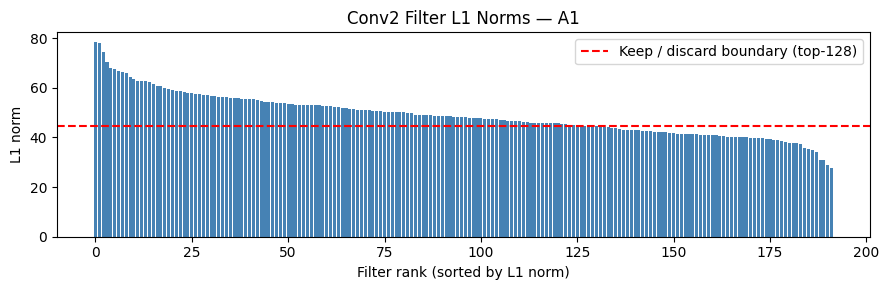

Keeping 128/192 Conv2 filters (33.3% reduction)
Selected filter indices (first 10): [0, 1, 3, 5, 8, 9, 12, 13, 15, 17] ...
AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 128, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(128, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classi

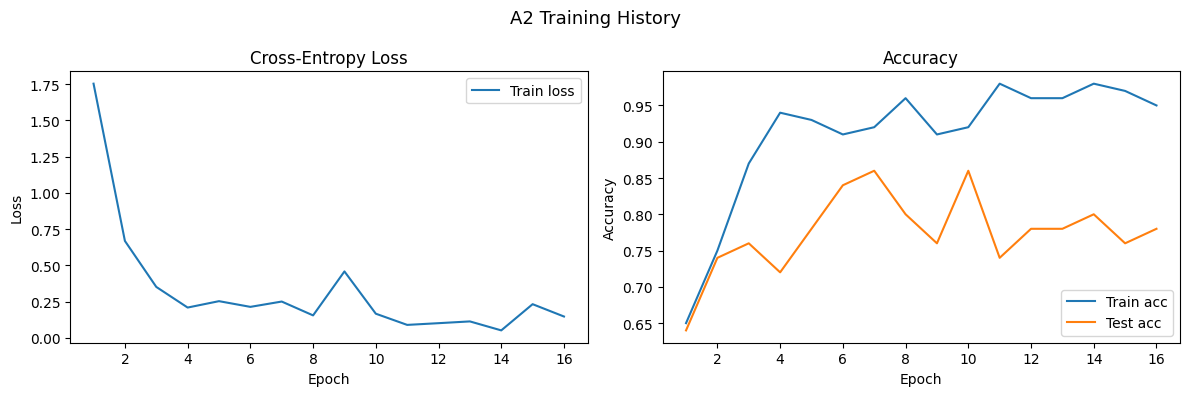

In [5]:
import copy
import torch
import torch.nn as nn
from torch import optim

# --- Inspect Conv2 and compute L1 norms ---

conv2_weights = a1.features[3].weight.data            # (192, 64, 5, 5)
print(f"Conv2 weight tensor shape: {tuple(conv2_weights.shape)}")

# L1 norm per output filter: sum of |w| over (in_channels, kH, kW)
l1_norms = conv2_weights.abs().sum(dim=[1, 2, 3])     # (192,)
print(f"L1 norm tensor shape: {tuple(l1_norms.shape)}")
print(f"  min  = {l1_norms.min():.4f}")
print(f"  mean = {l1_norms.mean():.4f}")
print(f"  max  = {l1_norms.max():.4f}")

K = 128   # keep 128 of 192, for a 33.3% reduction

# Visualise the norm distribution and the keep/discard boundary
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(range(len(l1_norms)), sorted(l1_norms.cpu().numpy(), reverse=True),
       color='steelblue')
ax.axhline(l1_norms.topk(K).values[-1].item(), color='red', linestyle='--',
           label=f'Keep / discard boundary (top-{K})')
ax.set_xlabel('Filter rank (sorted by L1 norm)')
ax.set_ylabel('L1 norm')
ax.set_title('Conv2 Filter L1 Norms — A1')
ax.legend()
plt.tight_layout()
plt.show()

# --- Select the top-K filters by L1 norm ---
top_k_indices = torch.argsort(l1_norms.cpu(), descending=True)[:K]
top_k_indices, _ = torch.sort(top_k_indices)
print(f"Keeping {K}/{conv2_weights.shape[0]} Conv2 filters "
      f"({100 * (1 - K / conv2_weights.shape[0]):.1f}% reduction)")
print(f"Selected filter indices (first 10): {top_k_indices[:10].tolist()} ...")

# --- Reconstruct Conv2 and Conv3 with sliced weights ---

a2 = copy.deepcopy(a1)

# Replace Conv2 with new output channels
old_conv2 = a2.features[3]
new_conv2 = nn.Conv2d(
    in_channels = old_conv2.in_channels,    # 64 (unchanged)
    out_channels = K,                       # 128
    kernel_size = old_conv2.kernel_size,    # (5, 5)
    stride = old_conv2.stride,              # (1, 1)
    padding = old_conv2.padding,            # (2, 2)
    bias = old_conv2.bias is not None,
)
# Apply sliced weights from Top-K filters to new Conv2
sel2 = top_k_indices.to(old_conv2.weight.device)
new_conv2.weight.data = old_conv2.weight.data[sel2].clone()          # (128,64,5,5)
new_conv2.bias.data   = old_conv2.bias.data[sel2].clone()            # (128,)
a2.features[3] = new_conv2

# Replace Conv3 with new input channels
old_conv3 = a2.features[6]   # still the original Conv3
new_conv3 = nn.Conv2d(
    in_channels = K,                         # 128 (must match new Conv2 out)
    out_channels = old_conv3.out_channels,   # 384 (unchanged)
    kernel_size = old_conv3.kernel_size,     # (3, 3)
    stride = old_conv3.stride,               # (1, 1)
    padding = old_conv3.padding,             # (1, 1)
    bias = old_conv3.bias is not None,
)
#Apply sliced weights to new Conv3
sel3 = top_k_indices.to(old_conv3.weight.device)
new_conv3.weight.data = old_conv3.weight.data[:, sel3, :, :].clone()
new_conv3.bias.data = old_conv3.bias.data.clone()                  # output-side, unchanged
a2.features[6] = new_conv3

a2.to(device)
print(a2)

# --- Verify the forward pass ---

a2.eval()
with torch.no_grad():
    out = a2(torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(device))
print(f"Output shape: {tuple(out.shape)}  (expected (1, {NUM_CLASSES}))")

# --- Freeze Conv1 & Conv2, identify trainable params ---
for param in a2.parameters():
    param.requires_grad = False
for layer in a2.features[6:]:                # Conv3, Conv4, Conv5 (ReLU/Pool have no params)
    for param in layer.parameters():
        param.requires_grad = True
for param in a2.classifier.parameters():
    param.requires_grad = True

print("A2 — params to learn:")
params_to_update_a2 = []
for name, param in a2.named_parameters():
    if param.requires_grad:
        params_to_update_a2.append(param)
        print(f"\t{name}")

# --- Parameter comparison (with delta) ---
print(f"\n{'Model':<6} {'Total params':>14} {'Trainable':>12}")
print("-" * 36)
totals = {}
for label, model in [('A1', a1), ('A2', a2)]:
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    totals[label] = total
    print(f"{label:<6} {total:>14,} {trainable:>12,}")
delta = totals['A1'] - totals['A2']
print(f"\nTotal params removed: {delta:,} "
      f"({100 * delta / totals['A1']:.2f}% of A1)")

# --- Train A2 (reuse train_validate + A1 hyperparameters) ---
A2_WEIGHTS = os.path.join(BASE_DIR, 'a2_weights.pth')
A2_HISTORY = os.path.join(BASE_DIR, 'a2_history.npy')

loaded = False
if os.path.exists(A2_WEIGHTS) and os.path.exists(A2_HISTORY):
    try:
        a2.load_state_dict(torch.load(A2_WEIGHTS, map_location=device))
        a2.to(device)
        history_a2 = np.load(A2_HISTORY, allow_pickle=True).item()
        loaded = True
        print(f"A2 weights loaded from {A2_WEIGHTS} — skipping training.")
    except (RuntimeError, ValueError) as e:
        print(f"Existing A2 checkpoint did not match current architecture "
              f"({e}). Retraining from the sliced weights.")

if not loaded:
    trainer_a2 = optim.Adam(params_to_update_a2, lr=lr, weight_decay=wd_lambda)
    history_a2 = train_validate(a2, train_loader, test_loader,
                                num_epochs, trainer_a2, loss, label="A2")
    torch.save(a2.state_dict(), A2_WEIGHTS)
    np.save(A2_HISTORY, history_a2)
    print(f"A2 weights and history saved to {BASE_DIR}.")

# --- Plot A2 training history ---
epochs_a2 = range(1, len(history_a2['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle(f"A2 Training History", fontsize=13)

ax1.plot(epochs_a2, history_a2['train_loss'], label='Train loss')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax1.set_title('Cross-Entropy Loss'); ax1.legend()

ax2.plot(epochs_a2, history_a2['train_acc'], label='Train acc')
ax2.plot(epochs_a2, history_a2['test_acc'],  label='Test acc')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy')
ax2.set_title('Accuracy'); ax2.legend()
plt.tight_layout()
plt.show()

## Part V - Evaluation and Comparison

Measures and compares both models across accuracy, speed, and size to assess whether removing filters preserved performance while reducing computational cost.


Layer                                            A1 params    A2 params      Delta
----------------------------------------------------------------------------------
  features.0.weight                                 23,232       23,232         +0
  features.0.bias                                       64           64         +0
  features.3.weight                                307,200      204,800   -102,400 <--
  features.3.bias                                      192          128        -64 <--
  features.6.weight                                663,552      442,368   -221,184 <--
  features.6.bias                                      384          384         +0
  features.8.weight                                884,736      884,736         +0
  features.8.bias                                      256          256         +0
  features.10.weight                               589,824      589,824         +0
  features.10.bias                                     256          256   

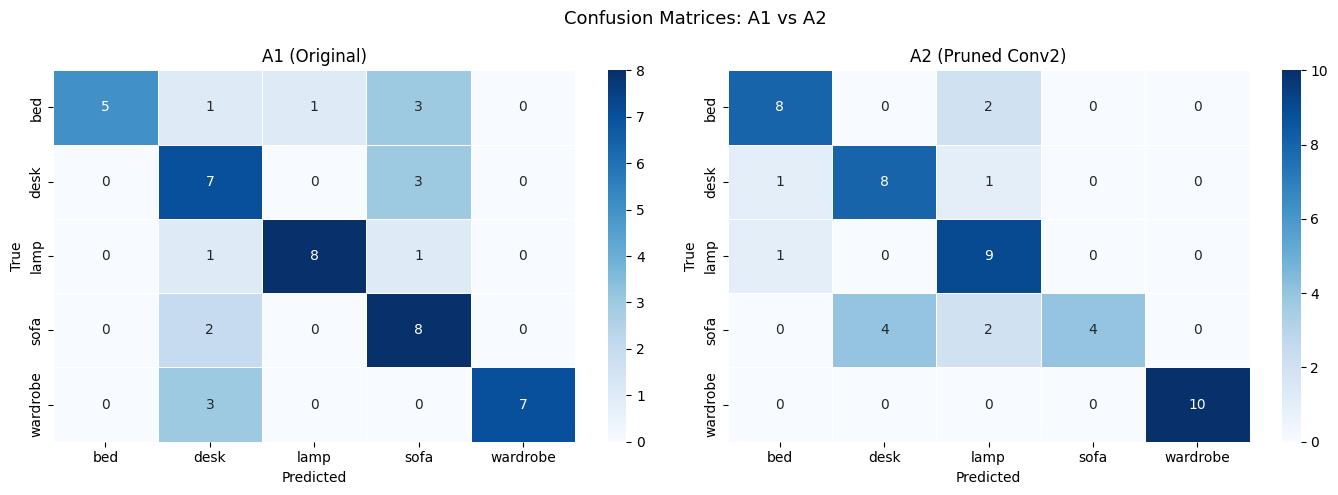


Model    Accuracy   Weighted F1
--------------------------------
A1          0.700         0.711
A2          0.780         0.770
Delta      +0.080        +0.059

--- A1 Classification Report ---
              precision    recall  f1-score   support

         bed      1.000     0.500     0.667        10
        desk      0.500     0.700     0.583        10
        lamp      0.889     0.800     0.842        10
        sofa      0.533     0.800     0.640        10
    wardrobe      1.000     0.700     0.824        10

    accuracy                          0.700        50
   macro avg      0.784     0.700     0.711        50
weighted avg      0.784     0.700     0.711        50

--- A2 Classification Report ---
              precision    recall  f1-score   support

         bed      0.800     0.800     0.800        10
        desk      0.667     0.800     0.727        10
        lamp      0.643     0.900     0.750        10
        sofa      1.000     0.400     0.571        10
    wardrob

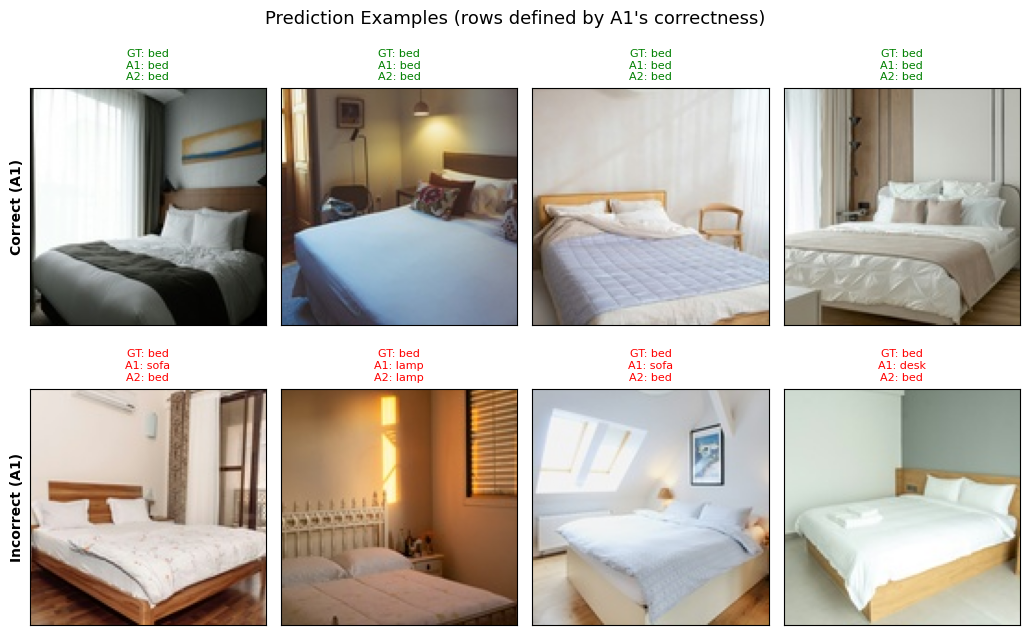

In [6]:
import copy
import time
from collections import OrderedDict

# --- Per-layer Parameter Comparison: A1 vs A2 ---

def param_table(model):
    rows = OrderedDict()
    for name, param in model.named_parameters():
        rows[name] = param.numel()
    return rows

rows_a1 = param_table(a1)
rows_a2 = param_table(a2)

# Preserve forward-pass (depth) order: A1 layers first, then any A2-only layers
all_layers = list(rows_a1.keys())
for k in rows_a2:
    if k not in rows_a1:
        all_layers.append(k)

print(f"\n{'Layer':<45} {'A1 params':>12} {'A2 params':>12} {'Delta':>10}")
print("-" * 82)
for layer in all_layers:
    n1 = rows_a1.get(layer, 0)
    n2 = rows_a2.get(layer, 0)
    delta = n2 - n1
    marker = " <--" if delta != 0 else ""
    print(f"  {layer:<43} {n1:>12,} {n2:>12,} {delta:>+10,}{marker}")
print("-" * 82)

total_a1 = sum(rows_a1.values())
total_a2 = sum(rows_a2.values())
print(f"  {'TOTAL':<43} {total_a1:>12,} {total_a2:>12,} {total_a2 - total_a1:>+10,}")
print(f"\n  Reduction: {100 * (total_a1 - total_a2) / total_a1:.2f}% of A1 total params removed")

# --- CPU Inference Time (averaged over 20 runs) ---

def measure_cpu_inference(model, input_tensor, n_runs=20):
    """Returns (mean_ms, std_ms) over n_runs on CPU.
    Uses a deep copy so the original model is never moved off its device.
    """
    model_cpu = copy.deepcopy(model).cpu().eval()
    x = input_tensor.cpu()
    times = []
    with torch.no_grad():
        # Warm-up pass (not counted)
        _ = model_cpu(x)
        for _ in range(n_runs):
            t0 = time.perf_counter()
            _ = model_cpu(x)
            times.append((time.perf_counter() - t0) * 1000)  # ms
    return float(np.mean(times)), float(np.std(times))

# Single-image batch reflects realistic deployment inference
sample_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)

mean_a1, std_a1 = measure_cpu_inference(a1, sample_input)
mean_a2, std_a2 = measure_cpu_inference(a2, sample_input)

print(f"\nCPU Inference Time (n=20 runs, batch_size=1)")
print(f"  A1: {mean_a1:6.2f} ms +/- {std_a1:.2f} ms")
print(f"  A2: {mean_a2:6.2f} ms +/- {std_a2:.2f} ms")
print(f"  Speedup: {mean_a1 / mean_a2:.3f}x")

# --- Collect Predictions ---

def get_predictions(model, data_loader):
    """Returns (all_true_labels, all_predicted_labels) as numpy arrays."""
    model.eval()
    all_true, all_pred = [], []
    with torch.no_grad():
        for X, y in data_loader:
            X = X.to(device)
            preds = model(X).argmax(dim=1).cpu().numpy()
            all_pred.extend(preds)
            all_true.extend(y.numpy())
    return np.array(all_true), np.array(all_pred)

true_a1, pred_a1 = get_predictions(a1, test_loader)
true_a2, pred_a2 = get_predictions(a2, test_loader)

# --- Confusion Matrices ---
cm_a1 = confusion_matrix(true_a1, pred_a1)
cm_a2 = confusion_matrix(true_a2, pred_a2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Confusion Matrices: A1 vs A2", fontsize=13)

for ax, cm, title in zip(axes, [cm_a1, cm_a2], ['A1 (Original)', 'A2 (Pruned Conv2)']):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=CLASSES, yticklabels=CLASSES,
                linewidths=0.5, linecolor='white', cbar=True)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.tight_layout()
plt.show()

# --- Accuracy, F1-Score, Classification Report ---
acc_a1 = accuracy_score(true_a1, pred_a1)
acc_a2 = accuracy_score(true_a2, pred_a2)
f1_a1  = f1_score(true_a1, pred_a1, average='weighted')
f1_a2  = f1_score(true_a2, pred_a2, average='weighted')

print(f"\n{'Model':<6} {'Accuracy':>10} {'Weighted F1':>13}")
print("-" * 32)
print(f"{'A1':<6} {acc_a1:>10.3f} {f1_a1:>13.3f}")
print(f"{'A2':<6} {acc_a2:>10.3f} {f1_a2:>13.3f}")
print(f"{'Delta':<6} {acc_a2 - acc_a1:>+10.3f} {f1_a2 - f1_a1:>+13.3f}")

print("\n--- A1 Classification Report ---")
print(classification_report(true_a1, pred_a1, target_names=CLASSES, digits=3))
print("--- A2 Classification Report ---")
print(classification_report(true_a2, pred_a2, target_names=CLASSES, digits=3))

# --- Visual Examples: Correct and Incorrect Predictions ---
n_show = 4
correct_idx = np.where(pred_a1 == true_a1)[0][:n_show]
wrong_idx   = np.where(pred_a1 != true_a1)[0][:n_show]

fig, axes = plt.subplots(2, n_show, figsize=(n_show * 2.6, 6.8))
fig.suptitle("Prediction Examples (rows defined by A1's correctness)", fontsize=13)

for col in range(n_show):
    # Top row: A1 correct
    if col < len(correct_idx):
        i = correct_idx[col]
        img = denorm(test_dataset[i][0]).permute(1, 2, 0).numpy()
        axes[0, col].imshow(img)
        axes[0, col].set_title(f"GT: {CLASSES[true_a1[i]]}\n"
                               f"A1: {CLASSES[pred_a1[i]]}\n"
                               f"A2: {CLASSES[pred_a2[i]]}",
                               fontsize=8, color='green')
    # Remove ticks but keep frame so set_ylabel below renders
    axes[0, col].set_xticks([]); axes[0, col].set_yticks([])

    # Bottom row: A1 incorrect
    if col < len(wrong_idx):
        i = wrong_idx[col]
        img = denorm(test_dataset[i][0]).permute(1, 2, 0).numpy()
        axes[1, col].imshow(img)
        axes[1, col].set_title(f"GT: {CLASSES[true_a1[i]]}\n"
                               f"A1: {CLASSES[pred_a1[i]]}\n"
                               f"A2: {CLASSES[pred_a2[i]]}",
                               fontsize=8, color='red')
    axes[1, col].set_xticks([]); axes[1, col].set_yticks([])

axes[0, 0].set_ylabel("Correct (A1)",   fontsize=10, fontweight='bold')
axes[1, 0].set_ylabel("Incorrect (A1)", fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()